### 지금까지 배웠던 개념
- 상태(state): 지금 어디에 있고, 어떤 상황인지. 예) 미로의 2행 3열
- 행동(action): 에이전트가 할 수 있는 선택(일). 예) 위/아래/왼쪽/오른쪽
- 보상(Reward): 행동 후 환경이 주는 숫자 피드백. 예) 출구 + 10, 충돌 - 1
- 정책(Policy): 상태를 보고 어떤 행동을 할지 정하는 규칙
- 가치(Value): 당장의 보상뿐 아니라 앞으로 얻을 보상까지 고려한 예상 점수
- 에피소드(Episode): 시작부터 종료까지 한 번의 시도


In [26]:
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from collections import deque

SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

In [27]:
if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
elif torch.xpu.is_available():
    DEVICE = torch.device('xpu')
else:
    DEVICE = torch.device('cpu')

print(DEVICE)

cpu


# **1. TD Learning**

- 어떤 길이 좋은지 판단하려면 원래는 끝까지 가서 받은 보상을 알아야 함
- 미로가 길거나 게임이 오래 지속되면 기다리는 동안 배울 수 없음
- TD는 한 칸 움직인 직후 예상치를 고침
 
```
1. A위치의 미래 점수를 지금 3점으로 예상
2, A에서 B로 이동(즉시 1점을 받음)
3. B에서 앞으로 얻을 점수는 5점이라고 예상
4. 미래 점수를 90%만 반영한다면 새로운 목표는 1 + 0.9 * 5 = 5.5점
5. 현재 예산 3점과 새 목표 5.5점의 차이는 +2.5점, 한 번의 경험만 믿고 3점을 곧바로 5.
5점으로 바꾸면 불안정할 수 있으므로 차의 10%인 0.25점만 반영해  3.25점으로 수정
```

$
delta = r + \gamma V(s') - V(s)
$
- V(s): 이동 전 상태 A에 대해 원래 예상했던 점수 예) 3
- r: 실제 이동 직후 받은 보상 예) 1
- V(s'): 이동 후 상태 B에서 앞으로 받을 것으로 예상하는 점수 예) 5
- $\gamma$: 미래 점수를 현재에 얼마나 반영할지 정하는 할인율 예) 0.8
- $\delta$: 예상과 새목표의 차이. 예) TD 오차 > 2.5

> 5.5점은 미래의 실제 정답이 아니라 현재의 추정값을 사용해 만든 임시 학습 목표. 이를 부트스트래핑(bootstrapping)이라고 부름

In [28]:
v_a, v_b = 3.0, 5.0
# alpha: 학습률. 새로운 경험을 얼마나 크게 반영할지
reward, gamma, alpha = 1.0, 0.9, 0.1
target = reward + gamma * v_b
td_error = target - v_a
new_v_a = v_a + alpha * td_error
print(f'목표={target:.2f}, 오차={td_error:.2f}, 수정된 V(A)={new_v_a:.2f}')
assert abs(new_v_a - 3.25) < 1e-9

목표=5.50, 오차=2.50, 수정된 V(A)=3.25


1. Monte Carlo
- 업데이트: 에피소드가 끝난 뒤
- 목표: 실제 관찰된 누적 보상
- 장점: 목표에 부트스트래핑 추정값을 사용하지 않음
- 주의점: 종료까지 기다려야 하고, 결과 반동이 클 수 있음

2. TD(Temporal Difference)
- 업데이트: 매 전이 직후
- 목표: 보상 + 다음 상태의 추정 가치
- 장점: 긴 에피소드에도 빠르게 갱싱
- 주의점: 추정값을 다시 사용해 편향이 생길 수 있음

> 둘 중 하나가 우월한 것은 아님. 환경과 학습 조건에 따라 선택

### Monte Carlo(MC)와 TD Learning의 학습 과정 및 성능 비교
1. 0번부터 6번까지 총 7개의 상태로 구성된 1차원 환경을 구현
- 로봇은 항상 3번 상태에서 시작
- 매번 왼쪽 또는 오른쪽으로 50% 확률로 이동
- 0번에 도착하면 보상 0점을 받고 종료
- 6번에 도착하면 보상 +1점을 받고 종료
- 그 외의 이동에서는 보상이 0점

2. Monte Carlo 학습 구현
- 에피소드가 종료된 후 학습
- 실제로 얻은 누적 보상을 계산
- 학습률을 적용하여 상태 가치를 업데이트

3. TD Learning 구현
- 다음 상태의 추정 가치를 이용
- TD Target과 TD Error를 계산
- 학습률을 적용하여 상태 가치를 업데이트

4. 학습 결과 비교
- 에피소드 수: 300
- 학습률: 0.05
- 할인률: 1.0
- 모든 상태 가치의 초기값: 0

5. 학습이 완료되면 아래 내용을 출력
- 각 상태의 실제 가치
- MC가 학습한 상태 가치
- TD가 학습한 상태 가치
- 에피소드별 MC와 TD의 RMSE 변화 그래프

6. 아래 질문에 답하세요
- MC와 TD Learning은 상태 가치를 업데이트하는 시점과 방법에서 어떤 차이가 있나요?
- RMSE가 작다는 것은 무엇을 의미하나요?
- 실습 결과에서 MC와 TD 중 어느 알고리즘이 더 빠르게 참값에 가까워졌나요? 그 이유는?

In [29]:
# Random Walk 에피소드 생성
def random_walk_episode(rng):
    state = 3  # 시작 상태
    transitions = []  # 상태 전이 기록

    while state not in (0, 6):  
        action = rng.choice([-1, 1])  # 왼쪽(-1) 또는 오른쪽(1) 무작위 선택
        nxt = state + action  # 다음 상태 계산
        done = nxt in (0, 6)  # 종료 상태 도달 여부 확인
        reward = 1.0 if nxt == 6 else 0.0  # 상태 6 도달 시 보상 1, 그 외 0

        transitions.append((state, reward, nxt, done)) 
        state = nxt  # 현재 상태 갱신

    return transitions  # 에피소드의 전체 전이 기록 반환

# 6에 도착할 확률은 0 1 2 3 4 5 6 에서 3의 위치에 있고 거기서 0과 6의 좌우대칭 
# 즉 중간에 있기 때문에 0에 도착할 확률과 6으로 도착할 확률 반이기 때문에 50%
# 쉽게말하면 0~6의 중간에 있어서 50%임
# 만약 2에 있다면 6에 먼저 도착할 확률이 33%

### 내가 넣은거임
![오른쪽 도착 확률](./images/오른쪽_도착_확률.png)


![왼쪽 도착 확률](./images/왼쪽_도착_확률.png)

In [30]:
# alpha: 학습률. 새로운 목표가 나타났다고 기존 값들 한번에 바꾸지 않는다는 뜻
# 새로운 정보와 기존 추정치의 차이를 0.05 반영

# Monte Carlo(MC)와 Temporal Difference(TD) 학습 비교
def compare_mc_td(episodes=300, alpha=0.05):
    rng = np.random.default_rng(SEED)  # 난수 생성기
    mc = np.zeros(7)  # MC 상태 가치 초기화
    td = np.zeros(7)  # TD 상태 가치 초기화
    mc_errors, td_errors = [], []  # 에피소드별 오차 저장
    truth = np.arange(1, 6) / 6  # 실제 상태 가치(6에 먼저 도착할 확률)


    # 각 상태에서 6에 먼저 도착할 실제 확률 출력
    for s, p in enumerate(truth, start=1): # 이 반복문 내가 넣은거임
        print(f"상태 {s} → 6에 먼저 도착할 확률: {p:.2%}")

    for _ in range(episodes):
        path = random_walk_episode(rng)  # Random Walk 에피소드 생성

        # TD(0): 다음 상태의 추정 가치를 이용하여 매 단계 학습
        for s, r, nxt, done in path:
            # td[s]: 현재 상태의 기존 예상 가치
            # r + (0 if done else td[nxt]): 지금 받은 보상 + 다음 상태의 예상 가치
            # r + (0 if done else td[nxt]) - td[s]: 예상이 얼마나 틀렸는지 나타내는 TD 오차
            td[s] += alpha * (r + (0 if done else td[nxt]) - td[s])

        # MC: 에피소드 종료 후 실제 누적 보상을 이용하여 학습 <- 지피티
        G = 0.0  # 현재 시점부터 에피소드 종료까지 얻은 누적 보상

        """
        역순 처리       현재 보상       누적 보상
        5 > 6           1               1
        4 > 5           0               1
        3 > 4           0               1
        """

        for s, r, nxt, done in reversed(path):
            G = r + G  # 누적 보상 계산
            mc[s] += alpha * (G - mc[s])  # MC 상태 가치 갱신
        mc_errors.append(np.sqrt(np.mean((mc[1:6]-truth)**2)))
        td_errors.append(np.sqrt(np.mean((td[1:6]-truth)**2)))
    return mc, td, mc_errors, td_errors

상태 1 → 6에 먼저 도착할 확률: 16.67%
상태 2 → 6에 먼저 도착할 확률: 33.33%
상태 3 → 6에 먼저 도착할 확률: 50.00%
상태 4 → 6에 먼저 도착할 확률: 66.67%
상태 5 → 6에 먼저 도착할 확률: 83.33%


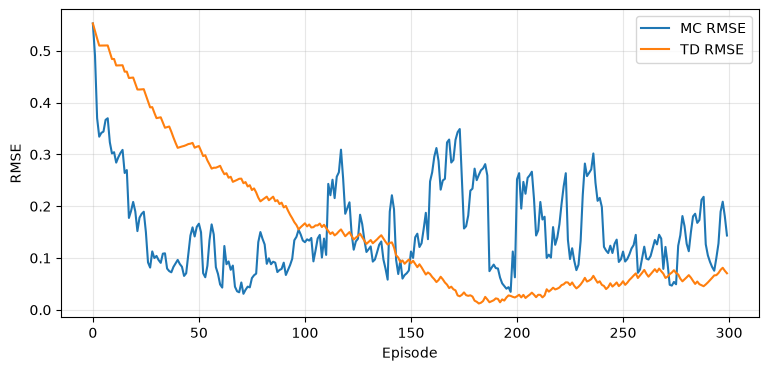

참값: [0.167 0.333 0.5   0.667 0.833]
MC  : [0.181 0.491 0.715 0.828 0.907]
TD  : [0.237 0.412 0.542 0.76  0.891]


In [31]:
mc_v, td_v, mc_err, td_err = compare_mc_td()
plt.figure(figsize=(9, 4))
plt.plot(mc_err, label='MC RMSE'); plt.plot(td_err, label='TD RMSE')
plt.xlabel('Episode'); plt.ylabel('RMSE'); plt.legend(); plt.grid(alpha=.3); plt.show()
print('참값:', np.round(np.arange(1,6)/6, 3))
print('MC  :', np.round(mc_v[1:6], 3))
print('TD  :', np.round(td_v[1:6], 3))

6. 아래 질문에 답하세요
- MC와 TD Learning은 상태 가치를 업데이트하는 시점과 방법에서 어떤 차이가 있나요?
    - MC: 에피소드가 완전히 종료된 후에 실제로 얻은 누적 보상(Return)을 이용하여 상태 가치를 업데이트
    - TD: 에피소드가 완전히 종료될 때까지 기다리지 않고, 한 번의 행동으로 얻은 보상과 다음 상태의 예상 가치를 이용해 현재 상태의 가치를 업데이트할 수 있음
- RMSE가 작다는 것은 무엇을 의미하나요?
    - 강화학습에서는 알고리즘이 학습한 상태 가치와 실제 상태 가치가 얼마나 차이 나는지 확인할 때 사용
    - 예) MC가 예측한 가치: 오차 0.02, TD가 예측한 가치: 오차 0.10 > MC 예측이 실제 가치에 더 가까움
    - RMSE가 작을수록 알고리즘이 학습한 상태 가치가 실제 정답에 가깝다는 의미 -> RMSE가 0이면 비교한 모든 상태의 예측 가치가 실제 가치와 정확히 일치한다는 뜻
    - 그쪽으로 갈 확률이 높다는 것을 의미?? <- 내가 쓴 거 
- 실습 결과에서 MC와 TD 중 어느 알고리즘이 더 빠르게 참값에 가까워졌나요? 그 이유는?
    - 일반적으로 Random 실습에서는 TD Learning보다 MC가 더 빠르게 참값에 가까워지는 경향이 있음
    - TD Learning은 매 이동에서 얻은 보상과 다음 상태의 추정 가치를 활용해 학습
    - 에피소드의 최종 결과만을 학습 목표로 사용하는 MC와 달리 이미 학습한 다른 상태의 가치 정보를 현재 상태의 학습에 활용
    - MC는 에피소드가 종료된 후 실제 누적 보상을 이용 > Random 환경에서는 같은 상태에서 출발하더라도 0번 또는 6번에 도착할 수 있기 때문에, 에피소드마다 누적 보상이 0 또는 1로 달라짐 > MC는 학습 목표의 변동성이 상대적으로 클 수 있음

### Grid 환경 구현 및 TD Learning을 이용한 상태 가치 학습

1. 5 * 5 크기의 격자 환경을 구현
- 시작 위치 (0, 0)
- 목표 위치 (4, 4)
- 장애물 위치: (1, 1), (1, 2), (3, 3)
- 행동: 상/하/좌/우
- 목표 도착 보상: +10
- 일반 이동 보상: -0.1
- 에피소드당 최대 이동 횟수: 100
- 로봇은 격자 범위를 벗어나거나 장애물로 이동하려고 하면 현재 위치에 머무름
- 단, 이동하지 못하더라도 이동 횟수는 증가하고 보상 -0.1이 적용
- 목표에 도착하면 에피소드가 종료되며, 최대 이동 횟수에 도달하면 해당 에프소드를 중단

2. 학습 조건
- 에피소드 수: 2000
- 학습률: 0.08
- 할인율: 0.95
- 행동 선택: 상/하/좌/우 무작위 선택
- 상태 가치 초기값: 모두 0

3. 시각화
- 학습된 5 * 5 상태 가치 배열 V
- 각 위치의 상태 가치를 표현한 Heatmap

4. 질문
- TD Learning에서 다음 상태 가치를 사용하는 이유?
- 목표 지점에 가까운 위치와 먼 위치의 상태 가치에는 어떤 차이가 나타나는지. 그 이유는 무엇인지?
- 장애물 주변의 상태 가치는 다른 위치와 어떤 차이가 있는지?

  0 1 2 3 4
0 0 0 0 0 0
1 0 0 0 0 0
2 0 0 0 0 0
3 0 0 0 0 0
4 0 0 0 0 1


In [32]:
# # 내가 한 거

# SIZE = 5
# HOME = (0, 0)
# BAR = (4, 4)
# GAMMA = 0.95
# ACTIONS = {
#     "up": (-1, 0),
#     "down": (1, 0),
#     "left": (0, -1),
#     "right": (0, 1)
# }
# ACTION_NAMES = ['up', 'down', 'left', 'right']
# ARROWS = {"up": "↑", "down": "↓", "left": "←", "right": "→", None: "·"}

# def grid_walk(start, actions):
#     if state in (HOME, BAR):
#             return state, 0.0, True
    
#         dr, dc = ACTIONS[action]
    
#         row, col = state
#         next_state = (min(max(row+dr, 0), SIZE-1), min(max(col+dc, 0), SIZE-1))
    
#         if next_state == HOME:
#             reward = 1.0
#         elif next_state == BAR:
#             reward = -1.0
#         else:
#             reward = 0.0
#         done = next_state in (HOME, BAR)
#         return next_state, reward, done





In [ ]:
class GridWorld:
    ACTIONS = [(-1, 0), (1, 0), (0, -1), (0, 1)]  # 상, 하, 좌, 우 이동

    def __init__(self, size=5, walls=((1, 1), (1, 2), (3, 3)), max_steps=100):
        self.size = size  # Grid 크기
        self.walls = set(walls)  # 벽 위치
        self.goal = (size-1, size-1)  # 목표 위치
        self.start = (0, 0)  # 시작 위치
        self.max_steps = max_steps  # 최대 이동 횟수
        
        # 시작 및 목표 위치에 벽이 없는지 확인
        assert self.goal not in self.walls and self.start not in self.walls  
        self.reset()  # 환경 초기화

    # 환경 초기화
    def reset(self):
        self.pos = self.start  # 현재 위치를 시작 위치로 설정
        self.steps = 0  # 이동 횟수 초기화
        return self.pos  # 초기 상태 반환

    # 행동에 따른 상태 전이
    def step(self, action):
        dr, dc = self.ACTIONS[action]  # 이동 방향
        r, c = self.pos  # 현재 위치
        candidate = (r + dr, c + dc)  # 다음 위치 계산

        # Grid 범위 내에 있고 벽이 아닌 경우 이동
        if (0 <= candidate[0] < self.size and 0 <= candidate[1] < self.size and candidate not in self.walls):
            self.pos = candidate  # 현재 위치 갱신

        self.steps += 1  # 이동 횟수 증가
        terminated = self.pos == self.goal  # 목표 도착 여부
        truncated = self.steps >= self.max_steps and not terminated  # 최대 이동 횟수 도달 여부
        reward = 10.0 if terminated else -0.1  # 목표 도착 시 +10, 그 외 -0.1
        return self.pos, reward, terminated, truncated  # 다음 상태, 보상, 종료 여부 반환

In [ ]:
env = GridWorld() 

V = np.zeros((env.size, env.size))  # 각 상태의 가치 0으로 초기화

alpha, gamma = 0.08, 0.95  # 학습률, 할인율
rng = np.random.default_rng(SEED)  # 난수 생성기

# TD Learning을 이용한 상태 가치 학습
for episode in range(2000):
    state = env.reset()  # 환경 초기화 및 시작 상태 반환

    while True:
        action = int(rng.integers(4))  # 상, 하, 좌, 우 중 무작위 행동 선택
        nxt, reward, terminated, truncated = env.step(action)  # 행동 실행 및 다음 상태, 보상, 종료 여부 반환
        bootstrap = 0 if terminated else V[nxt]  # 목표 도착 시 0, 그 외 다음 상태의 추정 가치 사용
        V[state] += alpha*(reward + gamma * bootstrap - V[state])  # TD(0) 상태 가치 갱신
        state=nxt  # 현재 상태 갱신

        if terminated or truncated:  # 목표 도착 또는 최대 이동 횟수 도달 시 종료
            break

랜덤 정책 아래 추정된 V(s):
[[-1.23 -1.26 -1.16 -0.82 -0.19]
 [-1.02  0.    0.   -0.27  0.56]
 [-0.84 -0.45 -0.06  0.31  1.9 ]
 [-0.5  -0.21  0.74  0.    5.2 ]
 [-0.33  0.69  2.36  5.57  0.  ]]


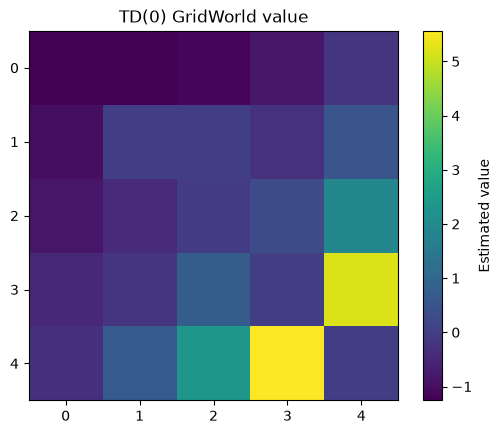

In [35]:
print('랜덤 정책 아래 추정된 V(s):')
print(np.round(V, 2))
plt.imshow(V, cmap='viridis')
plt.colorbar(label='Estimated value')
plt.title('TD(0) GridWorld value')
plt.show()

4. 질문
- TD Learning에서 다음 상태 가치를 사용하는 이유?
    - 현재 상태에서 앞으로 얻을 보상을 아직 정확히 알 수 없기 때문에 다음 상태에 대해 지금까지 학습한 예상 가치를 이용해 현재 상태의 가치를 추정하기 위함. 즉 현재 받은 보상과 다음 상태의 가치을 이용해 학습
- 목표 지점에 가까운 위치와 먼 위치의 상태 가치에는 어떤 차이가 나타나는지. 그 이유는 무엇인지?
    - 일반적으로 목표 지점에 가까운 위치는 먼 위치보다 상태 가지가 높게 나타나는 경향이 있음
- 장애물 주변의 상태 가치는 다른 위치와 어떤 차이가 있는지?
    - 장애물 주변의 상태 가치는 장애물이 없는 위치와 다르게 나타날 수 있으며, 목표로 이동하기 어려운 위치에서는 상대적으로 낮은 상태 가치가 나타나는 경향이 있음
    - 장애물 때문에 이동할 수 있는 경로가 제한되고, 목표까지 우회해야 하거나 제자리에서 시간을 소비할 가능성이 높아지기 때문

# **2. Q-Learning**
최적 행동 가치 Q에 가까워지도록 학습하여, 각 상태에서 Q가 큰 행동을 선택하는 것을 목표로 함

```
로봇이 갈림길 A에 있음
V(A) = 5 : A에 있을 때 앞으로 얼마나 좋은가?를 뜻
현재 왼쪽과 오른쪽 중 뭇엇을 선택할지는 알려주지 못함

Q(A, 왼쪽)=2, Q(A, 오른쪽)=8 : 오른쪽을 고를 수 있음(Q는 상태와 행동을 묶어 평가한 점수)
```

V(s): 이 상태에서 정책을 따라가면 앞으로 받을 예상 보상
Q(s, a): 이 상태에서 특정 행동 a를 먼저 선택하고 이후 정책을 따르면 받을 예상 보상

> 정책에 따라 V와 Q의 값도 달라질 수 있음. Q-Learning은 최적 행동 가치 Q에 가까워지도록 학습하여, 각 상태에서 Q가 큰 행동을 선택하는 것을 목표로 함

### Q-Learning의 계산 과정
1. 지금 (상태, 행동)의 기존 Q점수를 확인
2. 실제 행동을 해 보상을 받음
3. 다음 상태에서 가장 점수가 높은 행동의 Q값을 찾음
4. 지금 받은 보상 + 할인된 다음 상태 최고 점수를 새 목표로 삼음
5. 기존 점수와 목표의 차이를 학습률만큼 반영